# Support Vector Regression (SVR)

## Importing the libraries

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importing the dataset

In [87]:
dataset = pd.read_csv('Position_Salaries.csv')
X = dataset.iloc[:, 1:-1]
y = dataset.iloc[:, -1]

In [88]:
print(X)

   Level
0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10


In [89]:
X.values

# 2d array

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [90]:
print(y)

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64


In [91]:
y.values

# 1d array ---need to change to 2d 

array([  45000,   50000,   60000,   80000,  110000,  150000,  200000,
        300000,  500000, 1000000])

In [92]:
# We can only input 2d array in standerd scaler so reshaping y variable (X variable is already in 2d array)

y = (y.values).reshape(len(y),1)
X = X.values

In [93]:
print(y)
print("-----------------------------")
print(X)

[[  45000]
 [  50000]
 [  60000]
 [  80000]
 [ 110000]
 [ 150000]
 [ 200000]
 [ 300000]
 [ 500000]
 [1000000]]
-----------------------------
[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]]


## Feature Scaling

In [94]:
from sklearn.preprocessing import StandardScaler

# For X variables
sc_x = StandardScaler()
X = sc_x.fit_transform(X)

# For y-variable
sc_y = StandardScaler()
y = sc_y.fit_transform(y)

## Training the SVR model on the whole dataset

In [97]:
from sklearn.svm import SVR
regressor = SVR(kernel="rbf") # there are many kernals, do research
regressor.fit(X, y)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

## Predicting a new result

In [111]:
# Predicting for x = 6.3

sc_y.inverse_transform(regressor.predict(sc_x.transform([[6.3]])).reshape(-1, 1))

array([[158889.77747515]])

## Visualising the SVR results

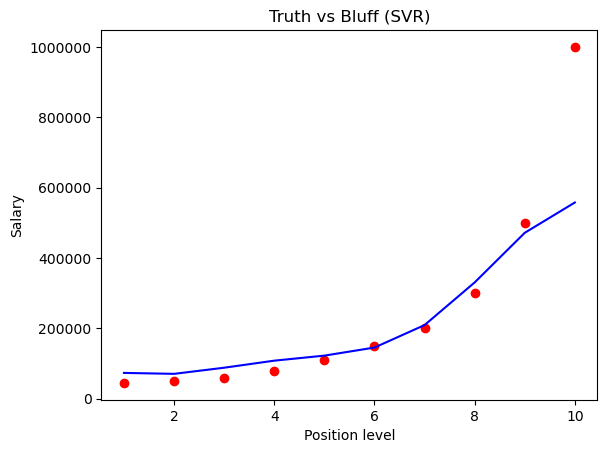

In [114]:
plt.scatter(x=sc_x.inverse_transform(X), y=sc_y.inverse_transform(y), color = "red")
plt.plot(sc_x.inverse_transform(X), sc_y.inverse_transform(regressor.predict(X).reshape(-1, 1)), color="blue")
plt.title("Truth vs Bluff (SVR)")
plt.xlabel("Position level")
plt.ylabel("Salary")
plt.ticklabel_format(style='plain', axis='y')
plt.show()

## Visualising the SVR results (for higher resolution and smoother curve)